# 01 – Exploring the EuroSAT dataset

Before training any model, you need to **look at your data**. Every ML project starts here. In this notebook you will:

1. Find the 10 land-cover classes
2. Count how many images each class has
3. Open one image and see what it looks like *to a computer* (spoiler: just numbers)
4. View a grid of examples from every class
5. Check whether colour alone is enough to tell classes apart

**How to use this notebook**
- Click a code cell and press **Shift + Enter** to run it.
- Run the cells **top to bottom, in order**. Later cells use variables created by earlier ones.
- Before running each cell, **guess what it will print**. Being wrong is how you learn.
- If things get weird: menu **Kernel → Restart Kernel and Run All Cells**.

## Step 1 – Import the tools

`import` loads a library (code someone else wrote) so you can use it.

| Library | What we use it for |
|---|---|
| `pathlib.Path` | Working with file and folder paths |
| `PIL.Image` | Opening image files (PIL = Python Imaging Library) |
| `numpy` (as `np`) | Working with big grids of numbers. Images *are* grids of numbers. |
| `matplotlib.pyplot` (as `plt`) | Drawing charts and showing images |

`import numpy as np` just gives it a short nickname so we can type `np` instead of `numpy`. Everyone uses these same nicknames.

In [3]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

## Step 2 – Find the classes

`DATA_DIR` is where the dataset lives. Writing it in CAPITALS is a convention meaning "this is a setting, don't change it later in the code".

Remember how the dataset is organised: **one folder per class, and the folder name is the label**. So to find the classes we just list the folders.

- `DATA_DIR.iterdir()` gives every item inside the folder (folders *and* files like `train.csv`)
- `if p.is_dir()` keeps only the folders
- `p.name` is just the folder's name, e.g. `"Forest"`
- `sorted(...)` puts them in alphabetical order

The alphabetical order matters later: PyTorch gives each class a number (0, 1, 2…) in exactly this order. So `AnnualCrop` will be class 0, `Forest` class 1, and so on.

**Predict:** how many classes will it print?

In [4]:
DATA_DIR = Path("C:/data/EuroSAT")

class_names = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())

print(len(class_names), "classes:")
for number, name in enumerate(class_names):
    print(number, name)

10 classes:
0 AnnualCrop
1 Forest
2 HerbaceousVegetation
3 Highway
4 Industrial
5 Pasture
6 PermanentCrop
7 Residential
8 River
9 SeaLake


`enumerate` gives you a counter alongside each item, so you get `0 AnnualCrop`, `1 Forest`, … That number is exactly what the model will output later: it predicts a number, and you look it up in this list to get the name.

## Step 3 – Count the images in each class

We build a **dictionary**: a lookup table that maps a key to a value, like `{"Forest": 3000, "River": 2500}`.

- `DATA_DIR / name` joins paths: `C:/data/EuroSAT` + `Forest` → `C:/data/EuroSAT/Forest`. (`pathlib` lets you use `/` for this.)
- `.glob("*.jpg")` finds every file ending in `.jpg` (`*` means "anything")
- `len(list(...))` counts them
- `f"{name:22}"` is an f-string: it puts the value of `name` into the text, padded to 22 characters so the numbers line up

**Why care?** If one class had 10× more images than another, the model could get lazy and just guess the big class a lot. This is called **class imbalance**.

In [5]:
counts = {}
for name in class_names:
    counts[name] = len(list((DATA_DIR / name).glob("*.jpg")))

for name, n in counts.items():
    print(f"{name:22} {n}")
print("Total:", sum(counts.values()))

AnnualCrop             3000
Forest                 3000
HerbaceousVegetation   3000
Highway                2500
Industrial             2500
Pasture                2000
PermanentCrop          2500
Residential            3000
River                  2500
SeaLake                3000
Total: 27000


Numbers are easier to compare as a picture. This draws a bar chart from the dictionary: the keys go along the bottom, the values set the bar heights.

`rotation=45` tilts the labels so they don't overlap.

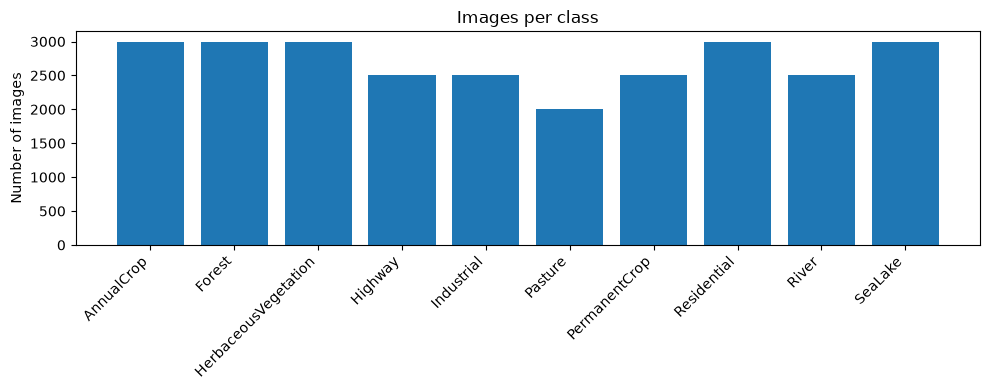

In [6]:
plt.figure(figsize=(10, 4))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Images per class")
plt.tight_layout()
plt.show()

The smallest class (Pasture, 2000) has two-thirds the images of the biggest (3000). That's a mild imbalance, not a serious one. Worth one sentence in your paper's Methods section.

## Step 4 – Open one image

- `next(...)` grabs the **first** file that `glob` finds
- `Image.open` loads it
- `img.size` is (width, height) in pixels
- `img.mode` is the colour format. `"RGB"` means each pixel has a Red, Green and Blue value.

Remember: each pixel covers **10 m × 10 m** of ground. **Predict:** how many metres wide is the patch of land in this image?

File: SeaLake_1.jpg
Size: (64, 64)
Mode: RGB


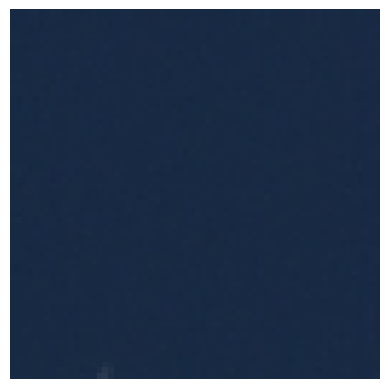

In [13]:
example_path = next((DATA_DIR / "SeaLake").glob("*.jpg"))
img = Image.open(example_path)

print("File:", example_path.name)
print("Size:", img.size)
print("Mode:", img.mode)

plt.imshow(img)
plt.axis("off")
plt.show()

Tiny and blurry, right? 64 × 64 pixels × 10 m = a 640 m × 640 m square of land. The model has to decide the land type from just this.

## Step 5 – What the computer actually sees

This is the most important idea in this notebook. **A computer never sees a picture. It sees a grid of numbers.**

`np.array(img)` converts the image into a numpy array (a grid of numbers):

- `.shape` is the size of the grid: **(height, width, colour channels)**
- `.dtype` is the number type. `uint8` = whole numbers from 0 to 255
- `pixels[0, 0]` is the top-left pixel: row 0, column 0. It holds 3 numbers: how red, how green, how blue (0 = none, 255 = maximum)

**Predict the shape before you run it.**

In [8]:
pixels = np.array(img)

print("Shape:", pixels.shape)
print("Number type:", pixels.dtype)
print("Smallest value:", pixels.min(), "  Largest value:", pixels.max())
print("Top-left pixel (R, G, B):", pixels[0, 0])
print("Average (R, G, B) of whole image:", pixels.mean(axis=(0, 1)).round(1))

Shape: (64, 64, 3)
Number type: uint8
Smallest value: 30   Largest value: 98
Top-left pixel (R, G, B): [40 63 79]
Average (R, G, B) of whole image: [38.9 61.1 77.6]


So one image = 64 × 64 × 3 = **12,288 numbers**. That's all the model ever gets.

`pixels.mean(axis=(0, 1))` means "average over the rows and the columns, but keep the 3 colour channels separate", giving you one average for red, one for green, one for blue.

**Surprise:** you'd expect green to be the biggest number for a forest, but it isn't. Blue is. And all the numbers are low (dark). Satellite photos are taken through the whole atmosphere, which scatters blue light (the same reason the sky is blue), so everything gets a bluish haze. This is a good example of why you **check the data instead of assuming**.

**Connection to training later:** remember the normalisation step in the guide (`mean=[0.485, 0.456, 0.406]`)? That converts these 0–255 numbers into small numbers centred around 0, because that's the range ResNet50 learned on. You now know what's being converted.

## Step 6 – Look at examples from every class

`plt.subplots(rows, columns)` makes a grid of mini-plots called `axes`. `axes[row, col]` picks one cell of that grid.

There are two loops, one inside the other:
- the **outer** loop goes through the 10 classes (one row each)
- the **inner** loop goes through 5 images of that class (one column each)

`sorted(...)[:5]` means "sort the file list, then take the first 5". `[:5]` is called **slicing**.

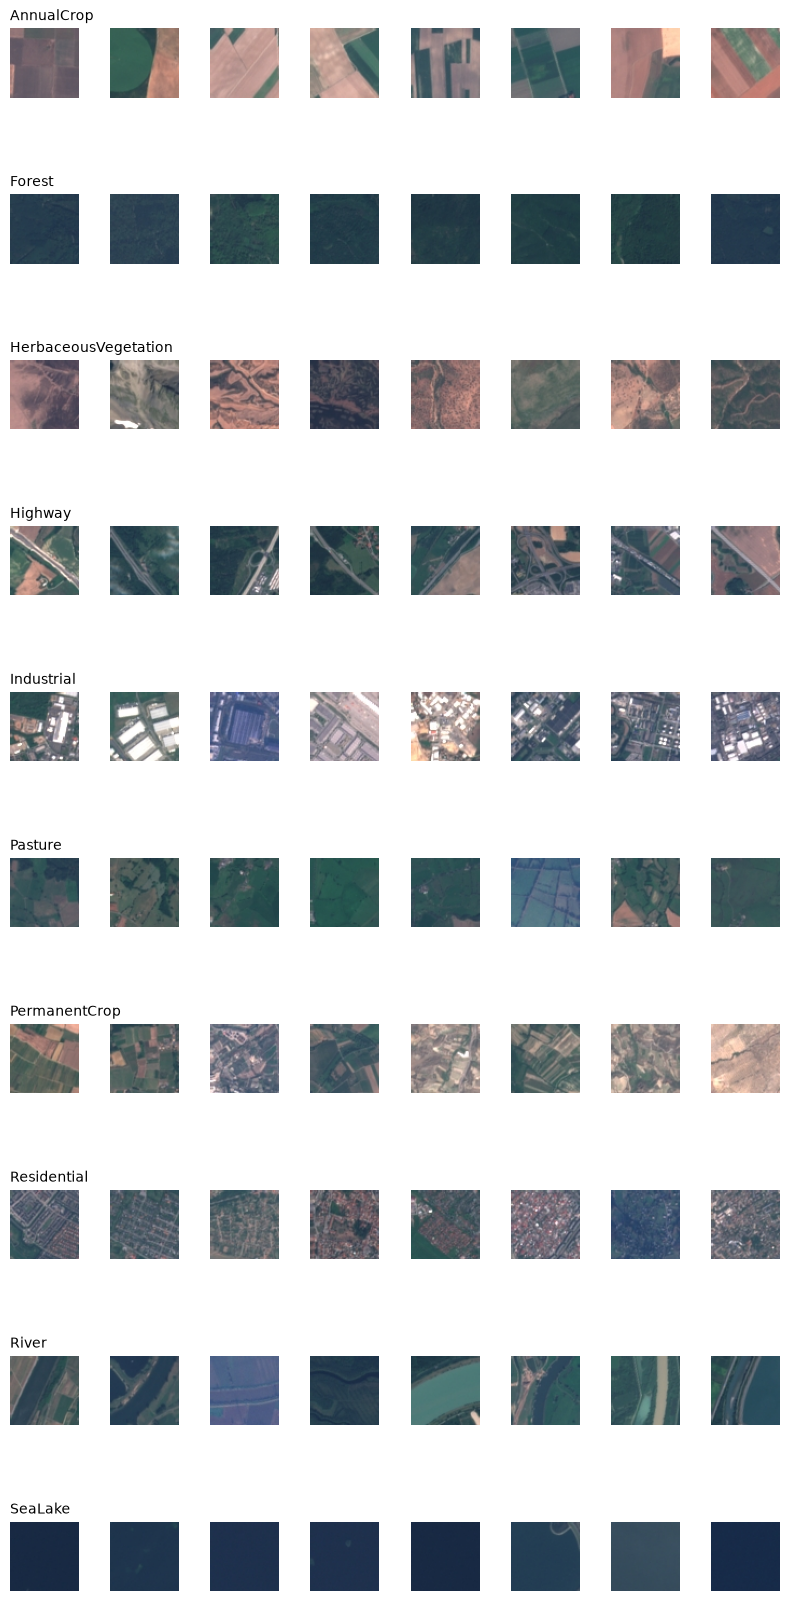

In [14]:
images_per_class = 8

fig, axes = plt.subplots(len(class_names), images_per_class, figsize=(8, 17))

for row, name in enumerate(class_names):
    paths = sorted((DATA_DIR / name).glob("*.jpg"))[:images_per_class]
    for col, path in enumerate(paths):
        ax = axes[row, col]
        ax.imshow(Image.open(path))
        ax.axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)

plt.tight_layout()
plt.show()

Look carefully. **Which classes would *you* struggle to tell apart?** Your answer here is a prediction of where the model will make mistakes. You'll check it against the confusion matrix in a later notebook.

## Step 7 – Is colour enough?

Here's a question: could we skip the fancy neural network and just say "mostly green = forest, mostly blue = sea"?

Let's test it. For each class, we average the colour of 200 images.

`[... for p in paths]` is a **list comprehension**: a short way to write a loop that builds a list. These two do the same thing:

```python
# long way
means = []
for p in paths:
    means.append(np.array(Image.open(p)).mean(axis=(0, 1)))

# short way
means = [np.array(Image.open(p)).mean(axis=(0, 1)) for p in paths]
```

`r, g, b = avg_colors[name]` unpacks the 3 numbers into 3 separate variables in one go.

This cell reads 2,000 images, so it takes a few seconds.

In [10]:
avg_colors = {}
for name in class_names:
    paths = sorted((DATA_DIR / name).glob("*.jpg"))[:200]
    means = [np.array(Image.open(p)).mean(axis=(0, 1)) for p in paths]
    avg_colors[name] = np.mean(means, axis=0)
    r, g, b = avg_colors[name]
    print(f"{name:22} R={r:5.1f}  G={g:5.1f}  B={b:5.1f}")

AnnualCrop             R=128.8  G=118.9  B=116.3
Forest                 R= 38.6  G= 63.6  B= 75.8
HerbaceousVegetation   R= 98.4  G= 98.7  B=103.8
Highway                R= 89.7  G= 97.6  B=103.7
Industrial             R=122.9  G=125.2  B=134.1
Pasture                R= 61.4  G= 87.4  B= 91.8
PermanentCrop          R=119.3  G=114.2  B=112.6
Residential            R= 99.5  G=103.4  B=112.5
River                  R= 66.3  G= 86.6  B= 97.1
SeaLake                R= 46.9  G= 71.7  B= 87.7


Now draw each class's average colour as a swatch.

- `np.array([...])` stacks the 10 averages into one array of shape (10, 3)
- `/ 255` scales 0–255 down to 0–1, which is what `imshow` wants for decimal numbers
- `[np.newaxis]` adds an extra dimension so the shape becomes (1, 10, 3): an "image" that's 1 pixel tall and 10 pixels wide

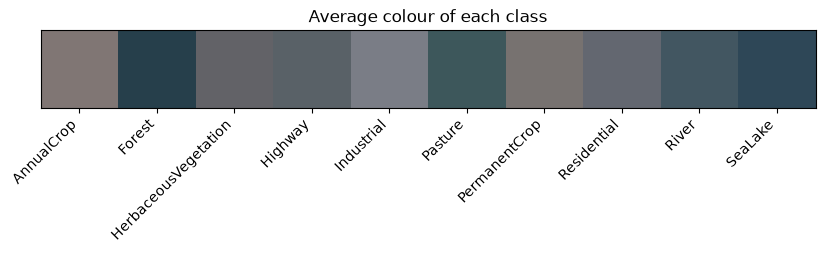

In [11]:
swatches = np.array([avg_colors[name] for name in class_names]) / 255

plt.figure(figsize=(10, 2))
plt.imshow(swatches[np.newaxis])
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks([])
plt.title("Average colour of each class")
plt.show()

**What this tells you:** several classes have almost the same average colour. Average colour throws away *where* the colours are, so it can't see the **patterns**: straight lines of a highway, the grid of a neighbourhood, the stripes of a crop field, the rough texture of a forest.

That's exactly what a **convolutional neural network (CNN)** is good at. It scans small windows across the image looking for edges, textures and shapes. That's why we need one, and why the next notebooks use ResNet50.

---

## Your turn

Do these by editing the code above and re-running the cell. Predict first, then run.

1. **Step 4:** change `"Forest"` to `"SeaLake"`. What do you predict the average (R, G, B) will look like compared to the forest?
2. **Step 6:** change `images_per_class` to `8`. What else changes in the picture?
3. **Step 7:** which two classes have the most similar swatch? Write your answer in a new markdown cell below (menu: **+**, then change the cell type from Code to Markdown).
4. **Challenge (uses loops):** we've *assumed* every image is 64 × 64. Real data often has surprises. Write a new cell that loops over every class and every image, and counts how many images are **not** 64 × 64.
   - Hint 1: you've already seen how to loop over classes, and how to get all the `.jpg` paths in a class.
   - Hint 2: `Image.open(path).size` gives you `(width, height)`. You can compare it with `!= (64, 64)`.
   - Hint 3: start a counter at 0 before the loops, add 1 to it inside the loop when the size is wrong, print it after.
   - It reads 27,000 images, so expect it to take 10–30 seconds.

## Check you understood

Answer these in your own words (in chat is fine):

- What are the three numbers in an image's shape, and what does each mean?
- Why do we need a CNN instead of just checking the average colour?
- Later, the model will receive **32 images at a time**, each resized to 224 × 224. Predict the shape of that batch.